# Short-Term Load Forecasting (STLF) — Evaluation & SHAP Explainability

This notebook takes the outputs of `02_model_training_and_evaluation.ipynb` (**day-ahead** forecasts: every day at 23:00, the 24 hours of the next day are forecast) and produces the figures for the report:

1. **Setup & data loading**: test-set predictions and the trained GRU model (proposed sequential model)
2. **Benchmark & time-series visualizations**: metric comparison, real vs. forecast demand, error by lead time and peak/valley analysis
3. **Explainability with SHAP (Expected Gradients)**: global feature importance, feature-effect plots and temporal profile for the GRU

All figures are saved at 300 DPI to `reports/figures/`.

---
## Section 1: Setup & Data Loading

### 1.1 Install dependencies
`shap` is not always pre-installed on Colab. TensorFlow is pre-installed.

In [1]:
%pip install -q shap

### 1.2 Mount Google Drive and define project paths
Inputs are read from `Project_IA/data/` and `Project_IA/models/`; figures are written to `Project_IA/reports/figures/`. Outside Colab, the current folder is used as the project root.

In [2]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/Project_IA'
except ImportError:
    BASE_DIR = os.path.abspath('.')

DATA_DIR = os.path.join(BASE_DIR, 'data')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
FIGURES_DIR = os.path.join(BASE_DIR, 'reports', 'figures')

PREDICTIONS_PATH = os.path.join(DATA_DIR, 'predicciones_test.csv')
COMPARISON_PATH = os.path.join(DATA_DIR, 'comparacion_modelos.csv')
DATASET_PATH = os.path.join(DATA_DIR, 'dataset_stlf_ecuador.csv')
GRU_MODEL_PATH = os.path.join(MODELS_DIR, 'gru_stlf.keras')
SCALERS_PATH = os.path.join(MODELS_DIR, 'scalers_stlf.joblib')

os.makedirs(FIGURES_DIR, exist_ok=True)
print('Figures will be saved to:', FIGURES_DIR)

Mounted at /content/drive
Figures will be saved to: /content/drive/MyDrive/Project_IA/reports/figures


### 1.3 Imports and plot style
Figures are displayed at screen resolution and **saved at 300 DPI**. A fixed color per model keeps every chart consistent.

In [3]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import tensorflow as tf
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.fontsize': 10,
})

MODELS = ['SARIMAX', 'XGBoost', 'LSTM', 'LightGBM', 'GRU']
PRED_COLS = {name: f'pred_{name.lower()}' for name in MODELS}
MODEL_COLORS = dict(zip(MODELS, sns.color_palette('tab10', n_colors=len(MODELS))))


def save_figure(fig, filename):
    path = os.path.join(FIGURES_DIR, filename)
    fig.savefig(path, dpi=300, bbox_inches='tight')
    print('Saved:', path)


print('shap       :', shap.__version__)
print('tensorflow :', tf.__version__)

shap       : 0.54.1
tensorflow : 2.21.0


### 1.4 Load test-set predictions
`predicciones_test.csv` holds the real demand (`real_mw`) and the day-ahead forecasts of the five models (SARIMAX baseline + four ML/DL models), all in MW.

In [4]:
pred_df = pd.read_csv(PREDICTIONS_PATH, parse_dates=['datetime']).set_index('datetime').sort_index()

expected = ['real_mw'] + list(PRED_COLS.values())
missing = [c for c in expected if c not in pred_df.columns]
assert not missing, f'Missing columns in predictions file: {missing}'

print(f'Test rows  : {len(pred_df)}')
print(f'Date range : {pred_df.index.min()} -> {pred_df.index.max()}')
pred_df.head()

Test rows  : 8895
Date range : 2024-12-26 09:00:00 -> 2025-12-31 23:00:00


,real_mw,pred_sarimax,pred_xgboost,pred_lstm,pred_lightgbm,pred_gru
datetime,,,,,,
2024-12-26 09:00:00,3578.71,2863.551634,3505.097659,3474.399856,3521.820531,3401.937201
2024-12-26 10:00:00,3639.32,2947.044536,3676.952400,3571.482506,3627.165775,3491.354794
2024-12-26 11:00:00,3674.53,3031.026815,3617.173732,3628.850425,3634.160022,3543.752121
2024-12-26 12:00:00,3635.83,3033.152938,3575.514833,3654.487642,3620.513984,3572.457049
2024-12-26 13:00:00,3631.42,3008.700476,3515.390751,3646.522818,3619.505148,3577.456866


### 1.5 Load the trained GRU model
The GRU is the proposed sequential model, so it is the model explained in Section 3. It was saved by notebook 02 in Keras format with the best weights restored by early stopping.

In [5]:
gru_model = tf.keras.models.load_model(GRU_MODEL_PATH)

print('Loaded model :', GRU_MODEL_PATH)
print('Input shape  :', gru_model.input_shape)
print(f'Parameters   : {gru_model.count_params():,}')

Loaded model : /content/drive/MyDrive/Project_IA/models/gru_stlf.keras
Input shape  : (None, 72, 11)
Parameters   : 24,984


---
## Section 2: Benchmark & Time Series Visualizations

### 2.1 Test-set metrics
MAE and MAPE are recomputed from the predictions file. Training time is not stored in the predictions, so it is read from `data/comparacion_modelos.csv` (exported by notebook 02).

In [6]:
y_true = pred_df['real_mw'].values

metrics = pd.DataFrame({
    name: {
        'MAE (MW)': np.mean(np.abs(y_true - pred_df[col].values)),
        'MAPE (%)': np.mean(np.abs((y_true - pred_df[col].values) / y_true)) * 100,
    }
    for name, col in PRED_COLS.items()
}).T

if os.path.exists(COMPARISON_PATH):
    comparison = pd.read_csv(COMPARISON_PATH, index_col='Model')
    metrics['Training Time (s)'] = comparison.loc[MODELS, 'Training Time (s)']
else:
    print('comparacion_modelos.csv not found: training time will be left empty.')
    metrics['Training Time (s)'] = np.nan

metrics.index.name = 'Model'
metrics.round(3)

,MAE (MW),MAPE (%),Training Time (s)
Model,,,
SARIMAX,243.212,6.681,11.476
XGBoost,104.454,2.742,227.607
LSTM,80.396,2.106,68.873
LightGBM,95.107,2.506,10.645
GRU,82.185,2.155,96.833


### 2.2 Figure: `metrics_comparison_bar.png`
MAE, MAPE and training time have different units, so each metric gets its own panel with a shared model ordering and color. Lower is better in all three panels. For XGBoost and LightGBM, training time is the total over their 24 lead-time models.

Saved: /content/drive/MyDrive/Project_IA/reports/figures/metrics_comparison_bar.png


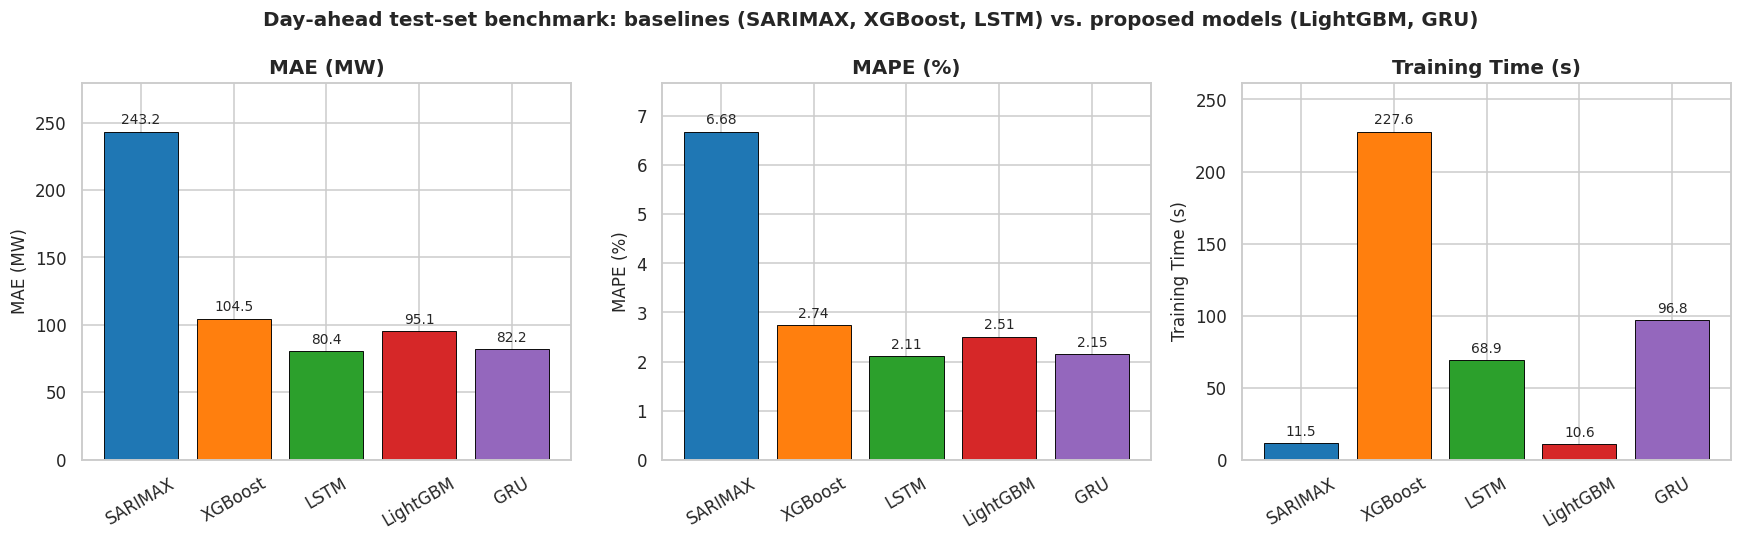

In [7]:
panels = [('MAE (MW)', '{:.1f}'), ('MAPE (%)', '{:.2f}'), ('Training Time (s)', '{:.1f}')]
colors = [MODEL_COLORS[m] for m in MODELS]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (metric, fmt) in zip(axes, panels):
    values = metrics.loc[MODELS, metric]
    bars = ax.bar(MODELS, values, color=colors, edgecolor='black', linewidth=0.6)
    for bar, value in zip(bars, values):
        if pd.notna(value):
            ax.annotate(fmt.format(value), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)
    ax.margins(y=0.15)

fig.suptitle('Day-ahead test-set benchmark: baselines (SARIMAX, XGBoost, LSTM) vs. proposed models (LightGBM, GRU)',
             fontsize=13, fontweight='bold')
fig.tight_layout()
save_figure(fig, 'metrics_comparison_bar.png')
plt.show()

### 2.3 Figure: `timeseries_forecast_test.png`
Real demand vs. the five day-ahead forecasts over a representative **744-hour (31-day) window** of the test set, where peak and valley capture can be inspected hour by hour. By default the last 744 hours are shown; set `WINDOW_START` to a timestamp (e.g. `'2025-03-01'`) to pick another month, or `WINDOW_HOURS = None` to plot the full test set. The highest and lowest real demand values in the window are marked.

Saved: /content/drive/MyDrive/Project_IA/reports/figures/timeseries_forecast_test.png


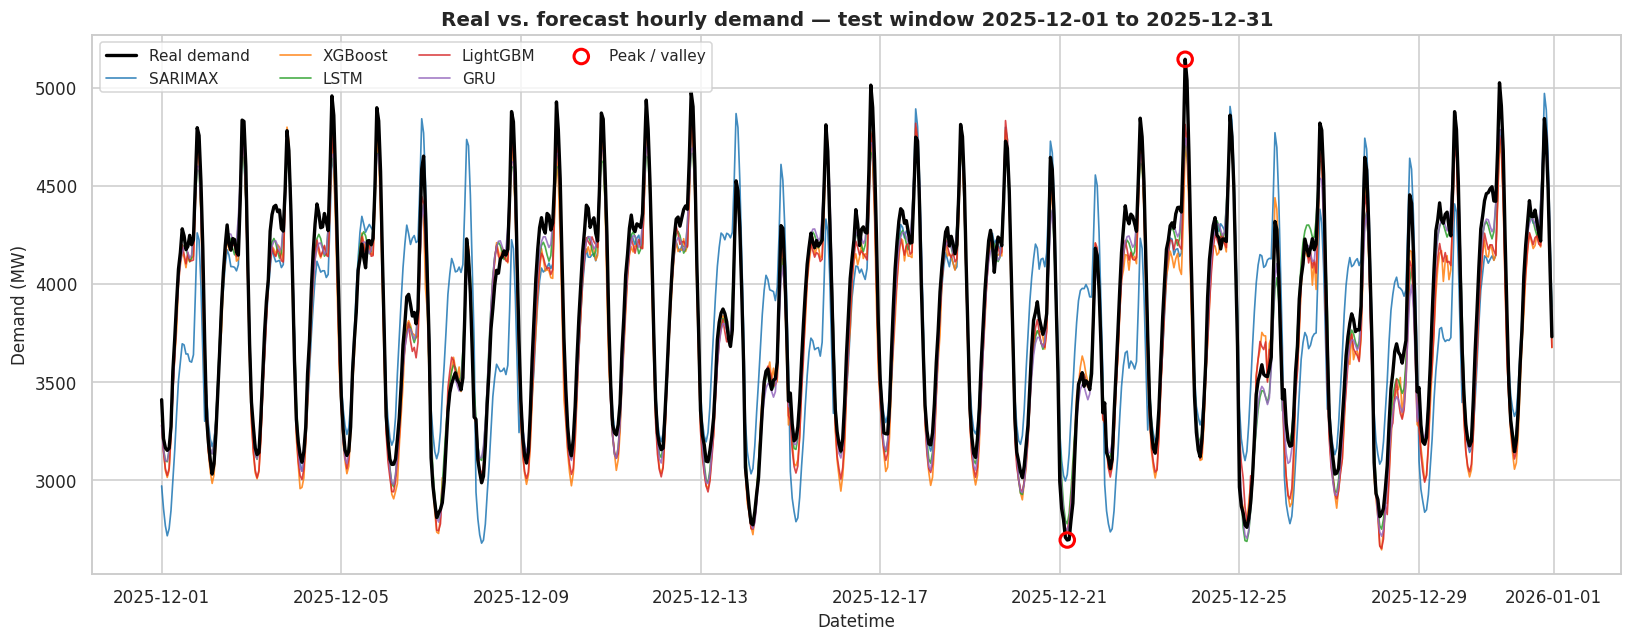

,real_mw,pred_sarimax,pred_xgboost,pred_lstm,pred_lightgbm,pred_gru
Peak,5145.8,4739.3,4695.4,4705.6,4813.8,4743.9
Valley,2695.5,3028.7,2743.6,2777.8,2746.9,2743.1


In [8]:
WINDOW_HOURS = 744
WINDOW_START = None

if WINDOW_HOURS is None:
    window = pred_df
elif WINDOW_START is None:
    window = pred_df.iloc[-WINDOW_HOURS:]
else:
    window = pred_df.loc[WINDOW_START:].iloc[:WINDOW_HOURS]

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(window.index, window['real_mw'], color='black', linewidth=2.2, label='Real demand', zorder=5)
for name, col in PRED_COLS.items():
    ax.plot(window.index, window[col], color=MODEL_COLORS[name], linewidth=1.1, alpha=0.85, label=name)

peak_time, valley_time = window['real_mw'].idxmax(), window['real_mw'].idxmin()
ax.scatter([peak_time, valley_time], window.loc[[peak_time, valley_time], 'real_mw'],
           s=90, facecolors='none', edgecolors='red', linewidths=2, zorder=6, label='Peak / valley')

ax.set_title(f'Real vs. forecast hourly demand — test window {window.index.min():%Y-%m-%d} to {window.index.max():%Y-%m-%d}')
ax.set_xlabel('Datetime')
ax.set_ylabel('Demand (MW)')
ax.legend(ncol=4, loc='upper left', frameon=True)
fig.tight_layout()
save_figure(fig, 'timeseries_forecast_test.png')
plt.show()

peak_valley = window.loc[[peak_time, valley_time], ['real_mw'] + list(PRED_COLS.values())]
peak_valley.index = ['Peak', 'Valley']
peak_valley.round(1)

### 2.4 Figure: `error_by_lead_time.png`
In the day-ahead setting, the hour 00:00 is forecast 1 h after the origin and the hour 23:00 is forecast 24 h after it. This figure shows how the MAE of each model grows with the lead time; the shaded band marks the evening peak (18:00–21:00, lead times 19–22 h), the most critical hours for dispatch and load-shedding planning.

Saved: /content/drive/MyDrive/Project_IA/reports/figures/error_by_lead_time.png


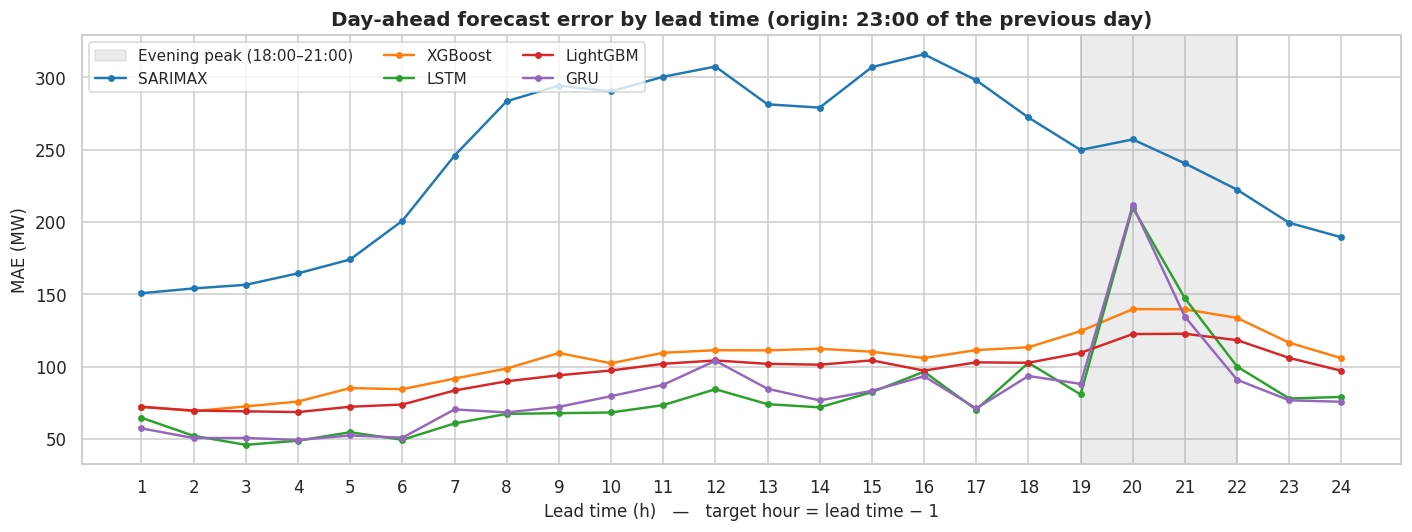

Lead time (h),1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
SARIMAX,150.8,154.1,156.6,164.5,174.1,200.8,245.9,283.5,294.4,290.4,...,307.2,316.0,298.1,272.3,249.9,257.2,240.6,222.4,199.4,189.5
XGBoost,72.3,69.2,72.4,75.8,85.1,84.4,91.7,98.7,109.4,102.3,...,110.3,105.9,111.4,113.3,124.5,139.7,139.7,133.6,116.5,105.8
LSTM,64.6,52.1,45.8,48.7,54.6,49.3,60.6,67.3,67.7,68.2,...,82.3,96.5,70.2,102.6,80.7,210.0,147.3,100.0,77.9,79.0
LightGBM,72.1,69.6,69.0,68.5,72.2,73.7,83.4,89.8,94.0,97.3,...,104.3,97.2,102.9,102.6,109.5,122.5,122.7,118.3,106.0,97.1
GRU,57.2,50.5,50.6,49.2,52.3,50.8,70.4,68.3,72.1,79.5,...,83.2,93.3,71.0,93.5,88.0,211.5,134.5,90.9,76.7,75.6


In [9]:
lead_time = pred_df.index.hour + 1  # lead time from the 23:00 origin of the previous day

lead_mae = pd.DataFrame({
    name: (pred_df[col] - pred_df['real_mw']).abs().groupby(lead_time).mean()
    for name, col in PRED_COLS.items()
})
lead_mae.index.name = 'Lead time (h)'

fig, ax = plt.subplots(figsize=(13, 5))
ax.axvspan(19, 22, color='grey', alpha=0.15, label='Evening peak (18:00–21:00)')
for name in MODELS:
    ax.plot(lead_mae.index, lead_mae[name], marker='o', markersize=3.5, linewidth=1.6,
            color=MODEL_COLORS[name], label=name)
ax.set_title('Day-ahead forecast error by lead time (origin: 23:00 of the previous day)')
ax.set_xlabel('Lead time (h)   —   target hour = lead time − 1')
ax.set_ylabel('MAE (MW)')
ax.set_xticks(range(1, 25))
ax.legend(ncol=3, loc='upper left')
fig.tight_layout()
save_figure(fig, 'error_by_lead_time.png')
plt.show()

lead_mae.round(1).T

### 2.5 Peak and valley analysis
Operational indicators per model over the whole test set:
- **MAE, MAPE and bias** in the evening peak band (18:00–21:00) and in the night valley band (02:00–05:00). Bias = mean(forecast − real): negative values mean **under-forecasting**, the dangerous direction when planning load shedding.
- **Daily peak**: mean absolute and signed error of the forecast daily maximum, and the percentage of days on which the forecast peak occurs at the same hour as the real one.
- **P95 |error|**: 95th percentile of the absolute error, a proxy for the reserve margin needed to cover forecast uncertainty.

In [10]:
hour = pred_df.index.hour
day = pred_df.index.normalize()
bands = {
    'Peak 18-21': (hour >= 18) & (hour <= 21),
    'Valley 02-05': (hour >= 2) & (hour <= 5),
}

real_daily_peak = pred_df['real_mw'].groupby(day).max()
real_peak_hour = pred_df['real_mw'].groupby(day).idxmax().dt.hour

rows = {}
for name, col in PRED_COLS.items():
    err = pred_df[col] - pred_df['real_mw']
    row = {}
    for band, mask in bands.items():
        row[f'{band} MAE (MW)'] = err[mask].abs().mean()
        row[f'{band} MAPE (%)'] = 100 * (err[mask].abs() / pred_df['real_mw'][mask]).mean()
        row[f'{band} bias (MW)'] = err[mask].mean()
    pred_daily_peak = pred_df[col].groupby(day).max()
    pred_peak_hour = pred_df[col].groupby(day).idxmax().dt.hour
    row['Daily peak MAE (MW)'] = (pred_daily_peak - real_daily_peak).abs().mean()
    row['Daily peak bias (MW)'] = (pred_daily_peak - real_daily_peak).mean()
    row['Peak hour match (%)'] = 100 * (pred_peak_hour == real_peak_hour).mean()
    row['P95 |error| (MW)'] = err.abs().quantile(0.95)
    rows[name] = row

peak_table = pd.DataFrame(rows).T
peak_table.index.name = 'Model'
print(f'Test days: {day.nunique()} | mean real demand in the peak band: '
      f"{pred_df['real_mw'][bands['Peak 18-21']].mean():.1f} MW")
peak_table.round(2).T

Test days: 371 | mean real demand in the peak band: 4416.6 MW


Model,SARIMAX,XGBoost,LSTM,LightGBM,GRU
Peak 18-21 MAE (MW),242.49,134.39,134.49,118.24,131.22
Peak 18-21 MAPE (%),5.56,3.00,2.99,2.64,2.94
Peak 18-21 bias (MW),-43.73,-102.11,-105.43,-87.03,-99.79
Valley 02-05 MAE (MW),174.00,79.43,49.62,70.87,50.74
Valley 02-05 MAPE (%),5.88,2.60,1.65,2.32,1.69
Valley 02-05 bias (MW),24.55,-64.86,5.79,-54.04,-8.43
Daily peak MAE (MW),255.98,139.10,196.53,122.60,189.67
Daily peak bias (MW),-54.00,-102.24,-192.57,-89.73,-185.02
Peak hour match (%),94.07,88.95,69.27,92.72,28.57
P95 |error| (MW),653.33,267.33,218.81,246.12,218.58


---
## Section 3: Model Explainability with SHAP (GRU)

### 3.1 Rebuild the test input windows `X_test_seq`
The GRU reads a window of **72 hourly rows** ending at 23:00 of the target day, with **11 features per step** (`lag_24h` + 3 temperatures + 4 cyclical + 3 calendar), and returns **24 outputs**, one per hour of the target day. Through `lag_24h`, the window carries the 72 hours of demand known at the forecast origin (23:00 of the previous day).

The windows are rebuilt exactly as in notebook 02 (section 1.8), one per test day, and every test hour is linked to its day window and to the output that forecasts it. The inputs are scaled with the scalers saved in notebook 02 (`models/scalers_stlf.joblib`). If that file is missing, the scalers are refitted on the same chronological training subset (first 72% of rows).

For the explanations, the demand channel is expressed relative to the forecast origin: `demand_o-0h` is the demand at the origin (23:00 of the previous day), `demand_o-1h` one hour earlier, and so on up to `demand_o-71h`.

In [11]:
HORIZON = 24  # day-ahead, same as notebook 02
N_LAGS = 72

TARGET = 'demand_mw'
WEATHER_COLS = ['app_temp_guayaquil', 'app_temp_quito', 'app_temp_cuenca']
ALL_LAG_COLS = [f'lag_{i}h' for i in range(1, HORIZON + N_LAGS)]  # lag_1h ... lag_95h
CYCLICAL_COLS = ['sin_hour', 'cos_hour', 'sin_dow', 'cos_dow']
CALENDAR_COLS = ['is_holiday', 'is_weekend', 'day_type']

SEQ_LEN = 72
DEMAND_SEQ_COL = f'lag_{HORIZON}h'
SEQ_FEATURES = [DEMAND_SEQ_COL] + WEATHER_COLS + CYCLICAL_COLS + CALENDAR_COLS

df = pd.read_csv(DATASET_PATH, parse_dates=['datetime']).set_index('datetime').sort_index()
df = df[WEATHER_COLS + ALL_LAG_COLS + CYCLICAL_COLS + CALENDAR_COLS + [TARGET]].dropna()

# Same chronological split as notebook 02: the fitting subset is the first 72% of rows
n_train = int(len(df) * 0.80)
n_fit = int(n_train * 0.90)

if os.path.exists(SCALERS_PATH):
    scalers = joblib.load(SCALERS_PATH)
    target_scaler, weather_scaler = scalers['target_scaler'], scalers['weather_scaler']
    SEQ_LEN = scalers.get('seq_len', SEQ_LEN)
    SEQ_FEATURES = scalers.get('seq_features', SEQ_FEATURES)
    assert scalers.get('horizon') == HORIZON, 'Scalers were saved for a different forecasting setup'
else:
    print('Scalers file not found: refitting on the training subset (same split as notebook 02).')
    train_part = df.iloc[:n_fit]
    target_scaler = MinMaxScaler().fit(train_part[[TARGET]])
    weather_scaler = MinMaxScaler().fit(train_part[WEATHER_COLS])

demand_min = target_scaler.data_min_[0]
demand_range = target_scaler.data_range_[0]

# Scaled per-step features: the exact input format the GRU was trained on
seq_scaled = df[SEQ_FEATURES].copy()
seq_scaled[WEATHER_COLS] = weather_scaler.transform(df[WEATHER_COLS])
seq_scaled[DEMAND_SEQ_COL] = (df[DEMAND_SEQ_COL] - demand_min) / demand_range
seq_matrix = seq_scaled.values.astype(np.float32)

# windows[j] covers rows j ... j + SEQ_LEN - 1
windows = sliding_window_view(seq_matrix, window_shape=SEQ_LEN, axis=0).transpose(0, 2, 1)
hour_all = df.index.hour.to_numpy()

# One window per test day, ending at 23:00 of the target day
test_pos = df.index.get_indexer(pred_df.index)
assert (test_pos >= 0).all(), 'Every test hour must exist in the dataset'
day_end_pos = test_pos + (23 - hour_all[test_pos])
test_ends = np.unique(day_end_pos)
X_test_seq = np.ascontiguousarray(windows[test_ends - (SEQ_LEN - 1)])

# For every test hour: its day window and the output (= hour of day) that forecasts it
test_window = np.searchsorted(test_ends, day_end_pos)
test_output = hour_all[test_pos]

# Explained features: demand relative to the forecast origin + context of the target hour
DEMAND_NAMES = [f'demand_o-{j}h' for j in range(N_LAGS)]
FEATURES = WEATHER_COLS + DEMAND_NAMES + CYCLICAL_COLS + CALENDAR_COLS
assert len(FEATURES) == 82

# Raw (unscaled) values for coloring SHAP plots: demand in MW at origin - j, context at the target hour
demand_raw = df[TARGET].to_numpy()
origin_pos = test_pos - test_output - 1  # 23:00 of the previous day
X_test_raw = pd.DataFrame(demand_raw[origin_pos[:, None] - np.arange(N_LAGS)],
                          columns=DEMAND_NAMES, index=pred_df.index)
context_cols = WEATHER_COLS + CYCLICAL_COLS + CALENDAR_COLS
X_test_raw[context_cols] = df.loc[pred_df.index, context_cols].values
X_test_raw = X_test_raw[FEATURES]

print('X_test_seq shape:', X_test_seq.shape, f'({len(test_ends)} test days)')

X_test_seq shape: (371, 72, 11) (371 test days)


### 3.2 Sanity check: reproduce the GRU test predictions
Before explaining the model, we confirm that the loaded GRU plus the rebuilt `X_test_seq` reproduce `pred_gru` from the predictions file. Differences of a fraction of a MW can appear from floating-point differences between GPU and CPU; a difference of tens of MW would mean the windows are misaligned.

In [12]:
Y_hat = gru_model.predict(X_test_seq, batch_size=256, verbose=0)  # (test days, 24)
pred_scaled = Y_hat[test_window, test_output]
pred_mw = pred_scaled * demand_range + demand_min

diff = np.abs(pred_mw - pred_df['pred_gru'].values)
print(f'Max  |reproduced - saved| prediction difference: {diff.max():.4f} MW')
print(f'Mean |reproduced - saved| prediction difference: {diff.mean():.4f} MW')

Max  |reproduced - saved| prediction difference: 0.0006 MW
Mean |reproduced - saved| prediction difference: 0.0001 MW


### 3.3 Compute SHAP values with Expected Gradients
TreeSHAP only works for tree models. For neural networks, SHAP uses **Expected Gradients** (the method behind `shap.GradientExplainer`): for each explained hour it draws reference windows from the training set (the *background*) and random points on the path between the reference and the input, and averages `(input − reference) × gradient`. It is implemented directly with `tf.GradientTape` so it works with any Keras version.

The GRU has 24 outputs, so each explained test hour is attributed through **the output that forecasts it** (its hour of day). The background consists of training windows ending at 23:00, i.e. the same kind of input as the test forecasts, and the base value of each hour is the mean background forecast of its output.

The result is one SHAP value per **time step and feature**, shape `(hours, 72, 11)`, multiplied by the demand range to express it **in MW**. Unlike TreeSHAP, the values are an approximation by sampling: base value + sum of SHAP values ≈ forecast, and the gap shrinks as `N_SAMPLES` grows.

Settings:
- `SHAP_SAMPLE`: number of random test hours to explain (`None` = full test set, much slower).
- `N_BACKGROUND`: number of reference windows taken from the training subset.
- `N_SAMPLES`: (reference, path point) draws per explained hour.

In [13]:
SHAP_SAMPLE = 1000
N_BACKGROUND = 500
N_SAMPLES = 200
BATCH_HOURS = 25  # explained hours per gradient batch (BATCH_HOURS * N_SAMPLES windows on the GPU at once)

rng = np.random.default_rng(42)

if SHAP_SAMPLE is not None and SHAP_SAMPLE < len(pred_df):
    sample_idx = np.sort(rng.choice(len(pred_df), SHAP_SAMPLE, replace=False))
else:
    sample_idx = np.arange(len(pred_df))

# Background: training windows ending at 23:00 (same kind of input as the test forecasts)
train_day_ends = np.arange(SEQ_LEN - 1, n_fit)[hour_all[SEQ_LEN - 1:n_fit] == 23]
background = np.ascontiguousarray(windows[rng.choice(train_day_ends, N_BACKGROUND, replace=False) - (SEQ_LEN - 1)])


def expected_gradients(x_batch, outputs):
    """SHAP values (scaled units) of output `outputs[i]` for window `x_batch[i]`, shape (n, SEQ_LEN, n_features)."""
    n = len(x_batch)
    x = np.repeat(x_batch, N_SAMPLES, axis=0)
    ref = background[rng.integers(0, N_BACKGROUND, size=n * N_SAMPLES)]
    alpha = rng.uniform(size=(n * N_SAMPLES, 1, 1)).astype(np.float32)
    mask = tf.one_hot(np.repeat(outputs, N_SAMPLES), HORIZON, dtype=tf.float32)
    z = tf.convert_to_tensor(ref + alpha * (x - ref))
    with tf.GradientTape() as tape:
        tape.watch(z)
        out = tf.reduce_sum(gru_model(z, training=False) * mask, axis=1)
    grads = tape.gradient(out, z).numpy()
    return ((x - ref) * grads).reshape(n, N_SAMPLES, SEQ_LEN, -1).mean(axis=1)


X_explain = X_test_seq[test_window[sample_idx]]
out_explain = test_output[sample_idx]
shap_seq_mw = np.concatenate([
    expected_gradients(X_explain[i:i + BATCH_HOURS], out_explain[i:i + BATCH_HOURS])
    for i in range(0, len(X_explain), BATCH_HOURS)
]) * demand_range

background_mean = gru_model.predict(background, verbose=0).mean(axis=0)  # mean forecast per output (scaled)
base_values_mw = background_mean[out_explain] * demand_range + demand_min

# Collapse (hours, 72, 11) into 82 named features:
# - lag_24h at step k of a window ending at row e is the demand at e - 95 + k = origin - (71 - k),
#   so reversing the steps gives demand_o-0h ... demand_o-71h
# - temperature, cyclical and calendar features are summed over the 72 steps of the window
lag_pos = SEQ_FEATURES.index(DEMAND_SEQ_COL)
shap_df = pd.DataFrame(shap_seq_mw[:, ::-1, lag_pos], columns=DEMAND_NAMES)
for feature in SEQ_FEATURES:
    if feature != DEMAND_SEQ_COL:
        shap_df[feature] = shap_seq_mw[:, :, SEQ_FEATURES.index(feature)].sum(axis=1)
shap_values_mw = shap_df[FEATURES].values

additivity_gap = np.abs(base_values_mw + shap_values_mw.sum(axis=1) - pred_mw[sample_idx])
print('SHAP values shape (per step) :', shap_seq_mw.shape)
print('SHAP values shape (82 feat.) :', shap_values_mw.shape)
print(f'Base value, mean (MW)        : {base_values_mw.mean():.1f}')
print(f'Additivity gap, mean (MW)    : {additivity_gap.mean():.2f}')
print(f'Additivity gap, p95 (MW)     : {np.percentile(additivity_gap, 95):.2f}')

SHAP values shape (per step) : (1000, 72, 11)
SHAP values shape (82 feat.) : (1000, 82)
Base value, mean (MW)        : 3306.1
Additivity gap, mean (MW)    : 22.42
Additivity gap, p95 (MW)     : 57.09


### 3.4 Feature groups
Global importance is the mean absolute SHAP value (in MW) per feature. Each feature is assigned to a group so the plots can highlight the three drivers of interest: **autoregressive demand known at the origin (72 h)**, **calendar (`day_type`, holidays, weekends)**, and **multi-regional temperature (Guayaquil, Quito, Cuenca)**.

Note: `demand_o-jh` is the demand j hours before the forecast origin (23:00 of the previous day). Each temperature, cyclical or calendar feature is the total effect of that variable over the whole 72-hour window.

In [14]:
def feature_group(feature):
    if feature in DEMAND_NAMES:
        return 'Autoregressive lags'
    if feature in WEATHER_COLS:
        return 'Regional temperature'
    if feature in CALENDAR_COLS:
        return 'Calendar'
    return 'Cyclical time'


GROUP_COLORS = {
    'Autoregressive lags': '#1f77b4',
    'Regional temperature': '#d62728',
    'Calendar': '#2ca02c',
    'Cyclical time': '#9467bd',
}

importance = pd.DataFrame({
    'feature': FEATURES,
    'mean_abs_shap_mw': np.abs(shap_values_mw).mean(axis=0),
})
importance['group'] = importance['feature'].map(feature_group)
importance = importance.sort_values('mean_abs_shap_mw', ascending=False).reset_index(drop=True)

group_importance = (importance.groupby('group')['mean_abs_shap_mw'].sum()
                    .sort_values(ascending=False).to_frame('total_mean_abs_shap_mw'))
group_importance['share_%'] = 100 * group_importance['total_mean_abs_shap_mw'] / group_importance['total_mean_abs_shap_mw'].sum()

print('Importance by feature group:')
display(group_importance.round(2))

print('Highlighted features (global rank out of 82):')
highlight = ['demand_o-0h', 'demand_o-1h', 'demand_o-23h', 'demand_o-47h', 'demand_o-71h', 'day_type'] + WEATHER_COLS
display(importance.reset_index().rename(columns={'index': 'rank'})
        .assign(rank=lambda d: d['rank'] + 1)
        .set_index('feature').loc[highlight].round(3))

Importance by feature group:


,total_mean_abs_shap_mw,share_%
group,,
Autoregressive lags,436.99,52.14
Calendar,264.23,31.53
Cyclical time,120.75,14.41
Regional temperature,16.11,1.92


Highlighted features (global rank out of 82):


,rank,mean_abs_shap_mw,group
feature,,,
demand_o-0h,8,28.818,Autoregressive lags
demand_o-1h,4,38.486,Autoregressive lags
demand_o-23h,17,7.684,Autoregressive lags
demand_o-47h,46,3.442,Autoregressive lags
demand_o-71h,72,1.418,Autoregressive lags
day_type,1,160.107,Calendar
app_temp_guayaquil,14,9.780,Regional temperature
app_temp_quito,54,2.660,Regional temperature
app_temp_cuenca,41,3.672,Regional temperature


### 3.5 Figure: `shap_summary_bar.png`
Top 20 features by mean |SHAP| (MW), colored by feature group. The bar length is the average amount (in MW) by which each feature moves the forecast away from the base value.

Saved: /content/drive/MyDrive/Project_IA/reports/figures/shap_summary_bar.png


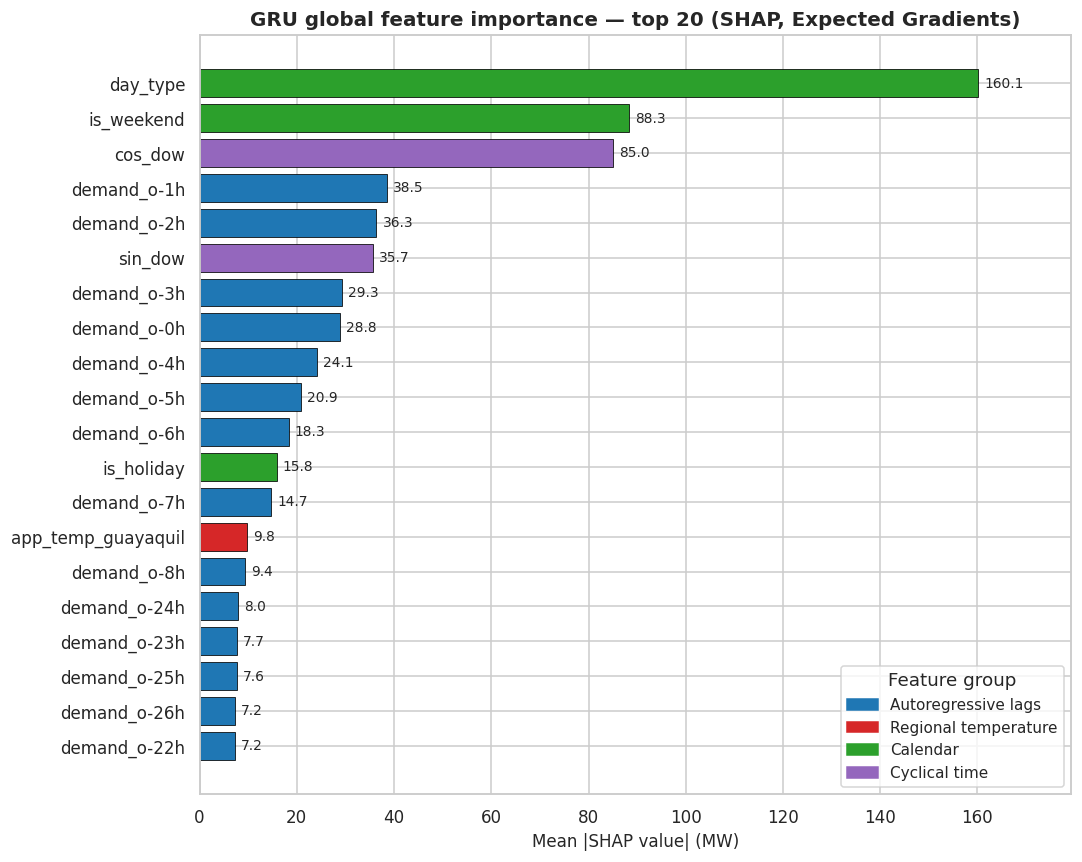

In [15]:
TOP_N = 20
top = importance.head(TOP_N).iloc[::-1]  # reversed so the most important feature is on top

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(top['feature'], top['mean_abs_shap_mw'],
               color=top['group'].map(GROUP_COLORS), edgecolor='black', linewidth=0.5)
for bar, value in zip(bars, top['mean_abs_shap_mw']):
    ax.annotate(f'{value:.1f}', (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
ax.legend(handles, GROUP_COLORS.keys(), title='Feature group', loc='lower right')
ax.set_title(f'GRU global feature importance — top {TOP_N} (SHAP, Expected Gradients)')
ax.set_xlabel('Mean |SHAP value| (MW)')
ax.set_ylabel('')
ax.margins(x=0.12)
fig.tight_layout()
save_figure(fig, 'shap_summary_bar.png')
plt.show()

### 3.6 Figure: `shap_summary_dot.png`
Each dot is one explained test hour. The horizontal position is the feature's contribution to the forecast (MW) and the color is the feature value (red = high, blue = low), shown in **original units** (MW for demand at the origin, °C for temperatures at the target hour). For example, high demand at the origin pushing the forecast up, or `day_type` = 1/2 (weekend/holiday) pushing it down, appear as red dots on the right and left respectively.

Saved: /content/drive/MyDrive/Project_IA/reports/figures/shap_summary_dot.png


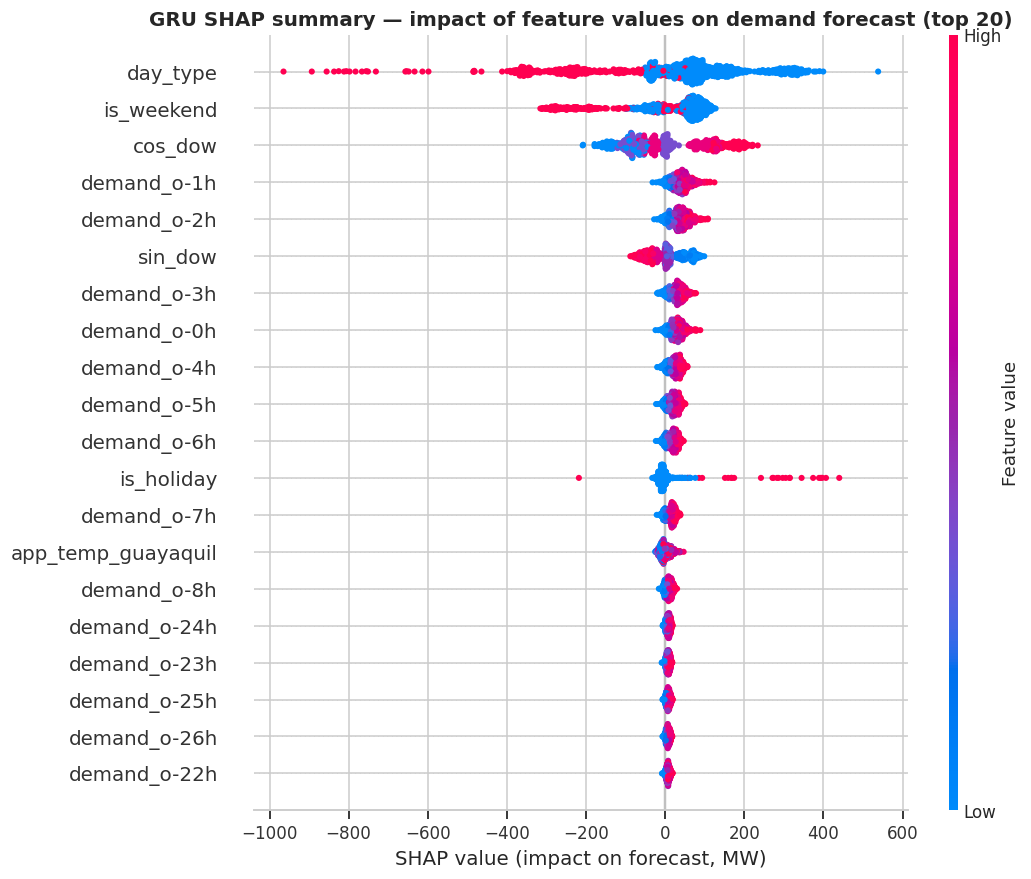

In [16]:
plt.figure()
shap.summary_plot(
    shap_values_mw,
    features=X_test_raw.iloc[sample_idx],
    feature_names=FEATURES,
    max_display=TOP_N,
    plot_type='dot',
    plot_size=(10, 8),
    show=False,
)
fig = plt.gcf()
fig.axes[0].set_title(f'GRU SHAP summary — impact of feature values on demand forecast (top {TOP_N})')
fig.axes[0].set_xlabel('SHAP value (impact on forecast, MW)')
save_figure(fig, 'shap_summary_dot.png')
plt.show()

### 3.7 Figure: `shap_temporal_profile.png`
Because the GRU reads a 72-hour sequence, SHAP also shows **how far back in time** the model looks.
- **Left:** mean |SHAP| (MW) of the demand known at the origin, by hours before the origin (0 = 23:00 of the previous day). Dashed lines mark 24 and 48 h (same hour on earlier days).
- **Right:** mean |SHAP| (MW) of the temperature, cyclical and calendar groups at each step of the window, counted back from 23:00 of the target day; the shaded band (0–23) is the target day itself.

Saved: /content/drive/MyDrive/Project_IA/reports/figures/shap_temporal_profile.png


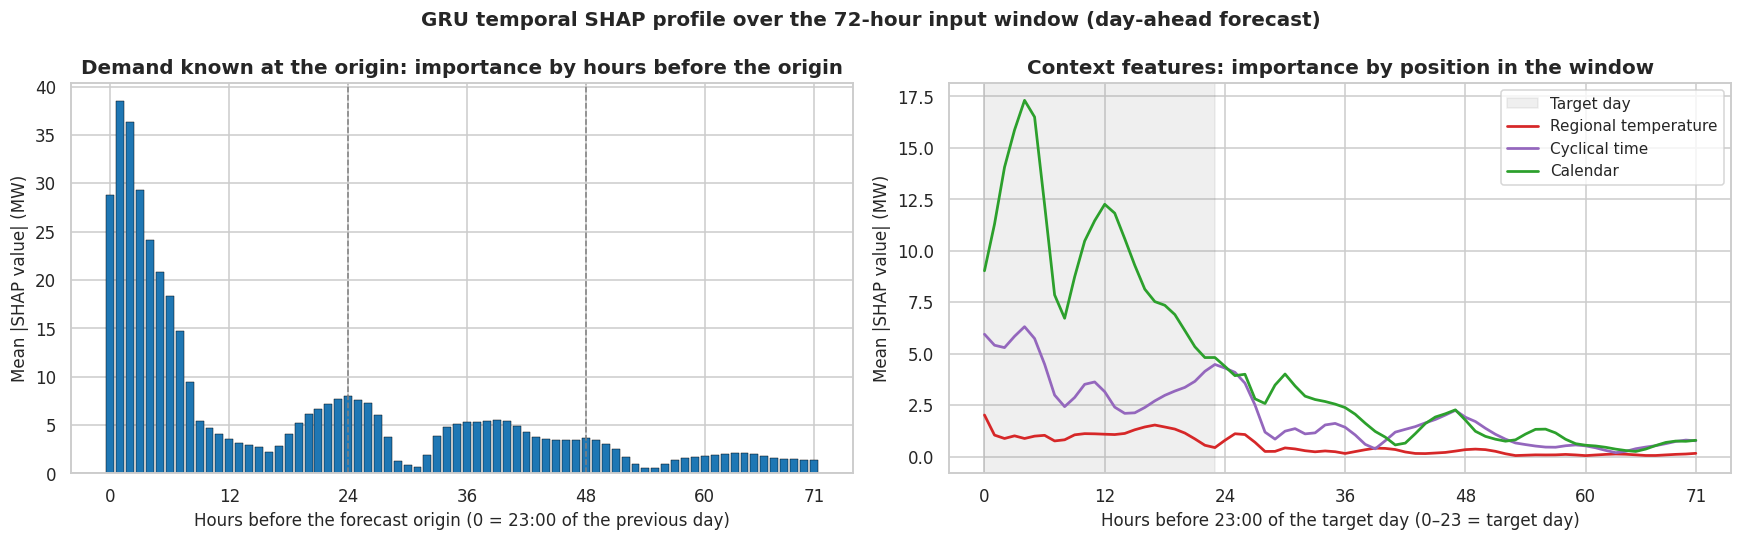

In [17]:
steps_back = np.arange(SEQ_LEN)  # demand: hours before the origin; context: hours before 23:00 of the target day

demand_profile = np.abs(shap_seq_mw[:, ::-1, lag_pos]).mean(axis=0)  # demand_o-0h ... demand_o-71h
context_groups = [('Regional temperature', WEATHER_COLS),
                  ('Cyclical time', CYCLICAL_COLS),
                  ('Calendar', CALENDAR_COLS)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(steps_back, demand_profile, color=GROUP_COLORS['Autoregressive lags'], edgecolor='black', linewidth=0.3)
for h in (24, 48):
    axes[0].axvline(h, color='grey', linestyle='--', linewidth=1)
axes[0].set_title('Demand known at the origin: importance by hours before the origin')
axes[0].set_xlabel('Hours before the forecast origin (0 = 23:00 of the previous day)')
axes[0].set_ylabel('Mean |SHAP value| (MW)')
axes[0].set_xticks([0, 12, 24, 36, 48, 60, 71])

axes[1].axvspan(0, 23, color='grey', alpha=0.12, label='Target day')
for group, cols in context_groups:
    idx = [SEQ_FEATURES.index(c) for c in cols]
    profile = np.abs(shap_seq_mw[:, ::-1, :][:, :, idx].sum(axis=2)).mean(axis=0)
    axes[1].plot(steps_back, profile, color=GROUP_COLORS[group], linewidth=1.8, label=group)
axes[1].set_title('Context features: importance by position in the window')
axes[1].set_xlabel('Hours before 23:00 of the target day (0–23 = target day)')
axes[1].set_ylabel('Mean |SHAP value| (MW)')
axes[1].set_xticks([0, 12, 24, 36, 48, 60, 71])
axes[1].legend()

fig.suptitle('GRU temporal SHAP profile over the 72-hour input window (day-ahead forecast)',
             fontsize=13, fontweight='bold')
fig.tight_layout()
save_figure(fig, 'shap_temporal_profile.png')
plt.show()

---
## Summary

All results correspond to **day-ahead** forecasts (issued at 23:00 for the 24 hours of the next day). Figures saved to `reports/figures/`:

| File | Content |
|---|---|
| `metrics_comparison_bar.png` | MAE, MAPE and training time for the 5 models |
| `timeseries_forecast_test.png` | Real vs. forecast demand over a 744-hour test window |
| `error_by_lead_time.png` | MAE of each model by lead time (1–24 h) |
| `shap_summary_bar.png` | GRU top-20 global feature importance (mean \|SHAP\|, MW), grouped by feature type |
| `shap_summary_dot.png` | Direction and magnitude of each feature's effect on the GRU forecast |
| `shap_temporal_profile.png` | How far back in the 72-hour window the GRU looks, per feature group |

The peak/valley table in **2.5** and the group table in **3.4** quantify, respectively, the operational behaviour of each model in the evening peak and how much of the GRU forecast is driven by past demand, calendar effects and regional temperatures.